Import libraries

In [3]:

# CELL 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_curve, roc_auc_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


All libraries imported successfully!
TensorFlow version: 2.21.0


Upload your dataset

In [4]:

# CELL 2: Upload the Mathematics dataset

uploaded = files.upload()

file_name = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
)

# Important: this dataset uses semicolons as separators
df = pd.read_csv(file_name, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Saving student-mat.csv to student-mat (1).csv
Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Understand the dataset

In [5]:

# CELL 3: Explore dataset structure

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Number of rows: 395
Number of columns: 33

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health        

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Check missing values and duplicates

In [6]:

# CELL 4: Data quality check

print("Missing values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

print("\nShape after duplicate removal:", df.shape)


Missing values:


,Missing Count
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Total missing values: 0
Duplicate rows: 0

Shape after duplicate removal: (395, 33)


Outlier analysis

In [7]:

# CELL 5: Detect possible outliers using IQR

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

outlier_summary = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": count
    })

display(pd.DataFrame(outlier_summary))

print("Outliers are identified, not automatically deleted.")


,Feature,Lower Bound,Upper Bound,Potential Outliers
0,age,13.0,21.0,1
1,Medu,-1.0,7.0,0
2,Fedu,0.5,4.5,2
3,traveltime,-0.5,3.5,8
4,studytime,-0.5,3.5,27
5,failures,0.0,0.0,83
6,famrel,2.5,6.5,26
7,freetime,1.5,5.5,19
8,goout,-1.0,7.0,0
9,Dalc,-0.5,3.5,18


Outliers are identified, not automatically deleted.


Create the target column

0 = Not Pass, 1 = Pass
Pass
1    265
0    130
Name: count, dtype: int64

Class distribution in percentage:
Pass
1    67.09
0    32.91
Name: proportion, dtype: float64


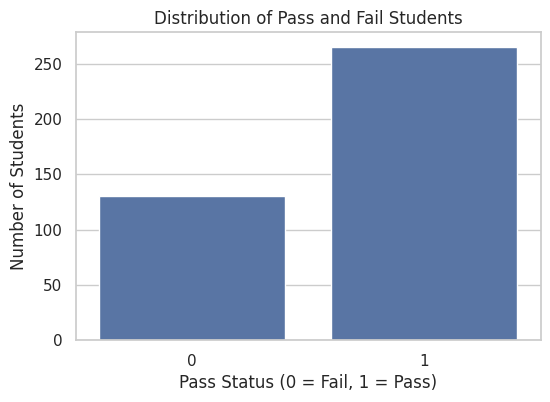

In [8]:

# CELL 6: Create pass/fail target

df["Pass"] = (df["G3"] >= 10).astype(int)

print("0 = Not Pass, 1 = Pass")
print(df["Pass"].value_counts())

print("\nClass distribution in percentage:")
print((df["Pass"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Pass")
plt.title("Distribution of Pass and Fail Students")
plt.xlabel("Pass Status (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")
plt.show()


Visualization 1: Grade distribution

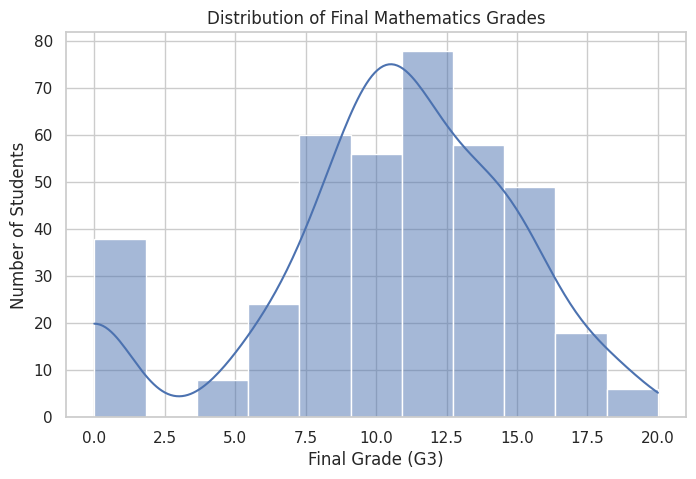

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64
Mean final grade: 10.42
Median final grade: 11.0


In [9]:

# CELL 7: Distribution of final grades

plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=11, kde=True)
plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

print(df["G3"].describe())
print("Mean final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", df["G3"].median())


Visualization 2: Study time and final grades

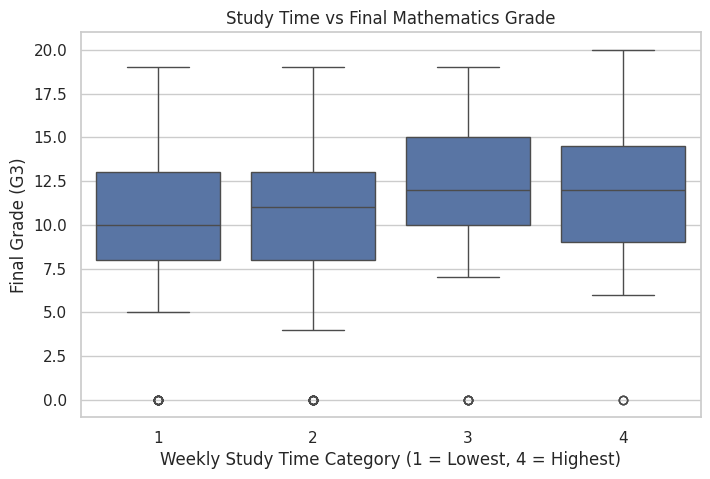

,count,mean,median
studytime,,,
1,105,10.05,10.0
2,198,10.17,11.0
3,65,11.40,12.0
4,27,11.26,12.0


In [10]:

# CELL 8: Study time versus final grade

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Study Time vs Final Mathematics Grade")
plt.xlabel("Weekly Study Time Category (1 = Lowest, 4 = Highest)")
plt.ylabel("Final Grade (G3)")
plt.show()

display(df.groupby("studytime", observed=True)["G3"].agg(
    ["count", "mean", "median"]
).round(2))


Visualization 3: Absences and grades

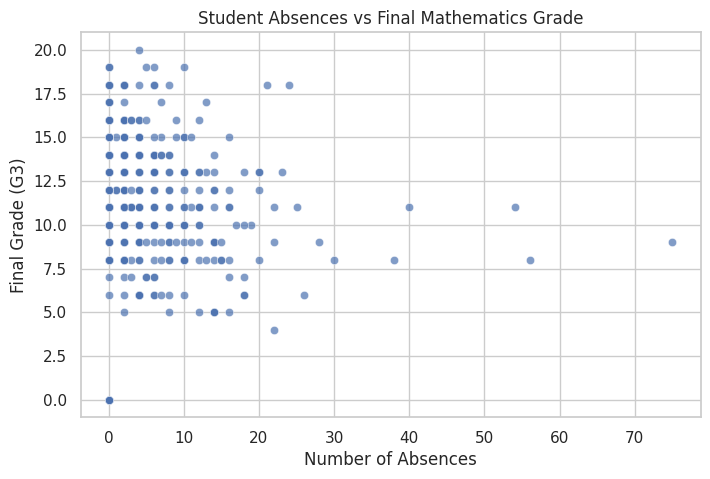

Correlation between absences and final grade: 0.034


In [11]:

# CELL 9: Absences versus final grade

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.7)
plt.title("Student Absences vs Final Mathematics Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()

print(
    "Correlation between absences and final grade:",
    round(df["absences"].corr(df["G3"]), 3)
)


Visualization 4: Correlation heatmap

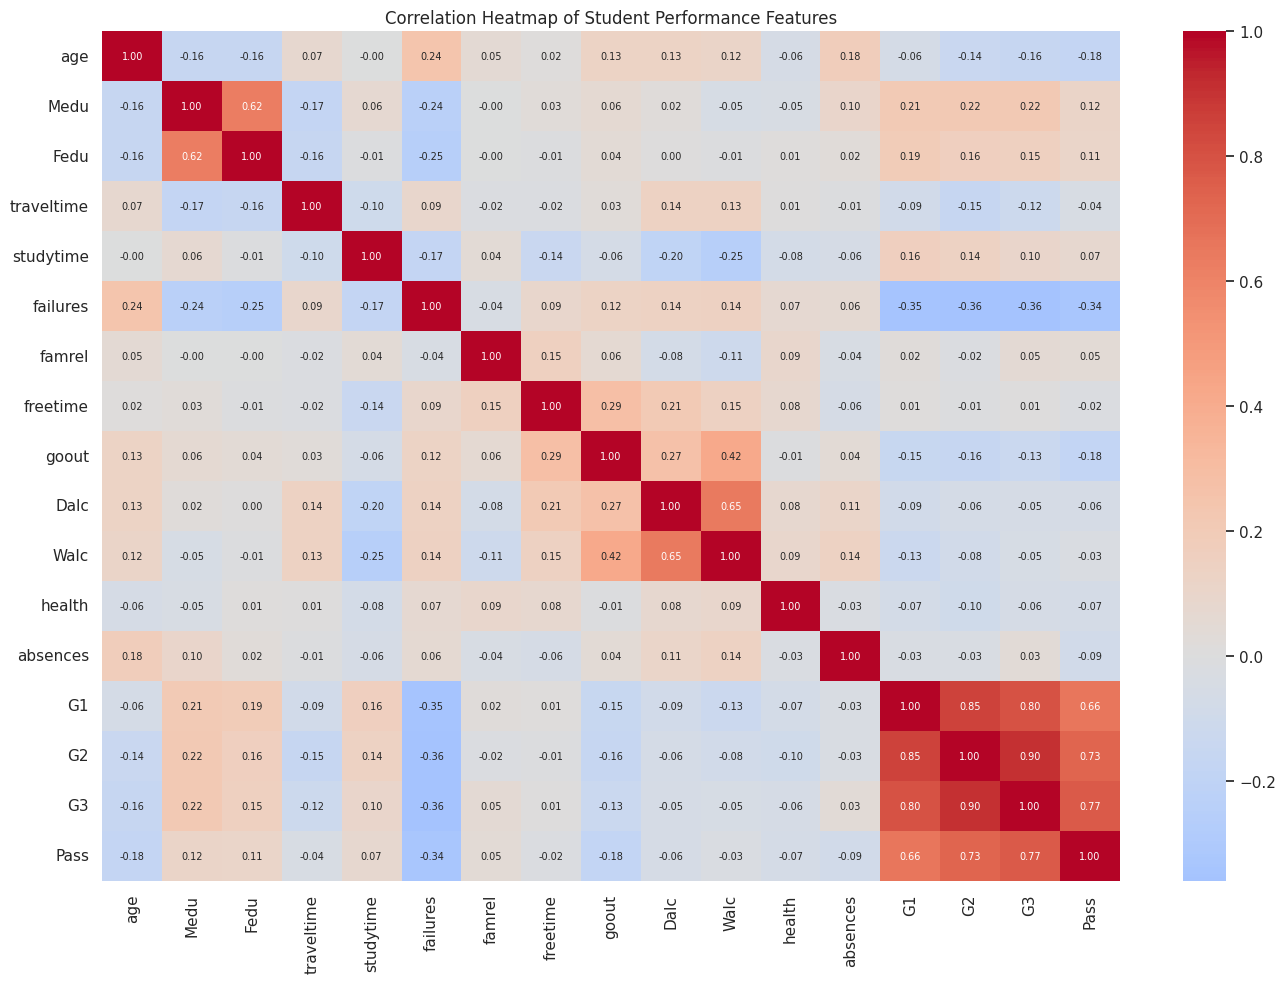

In [12]:

# CELL 10: Correlation among numerical features

plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap of Student Performance Features")
plt.tight_layout()
plt.show()


Visualization 5: Gender and final grades

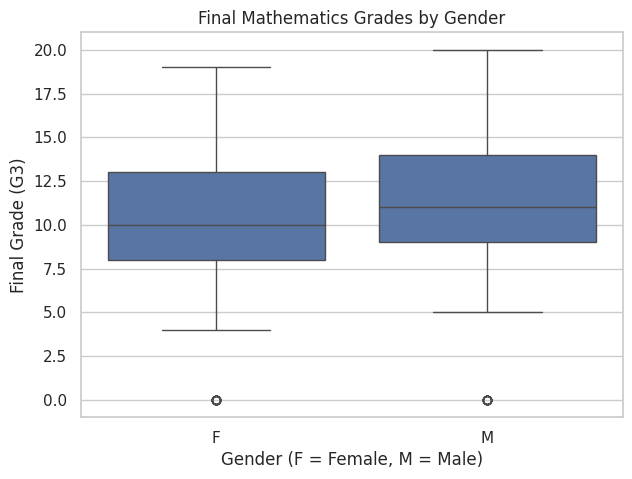

,count,mean,median
sex,,,
F,208,9.97,10.0
M,187,10.91,11.0


In [13]:

# CELL 11: Compare final grades by gender

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="sex", y="G3")
plt.title("Final Mathematics Grades by Gender")
plt.xlabel("Gender (F = Female, M = Male)")
plt.ylabel("Final Grade (G3)")
plt.show()

display(df.groupby("sex", observed=True)["G3"].agg(
    ["count", "mean", "median"]
).round(2))


Visualization 6: Parental education and student performance

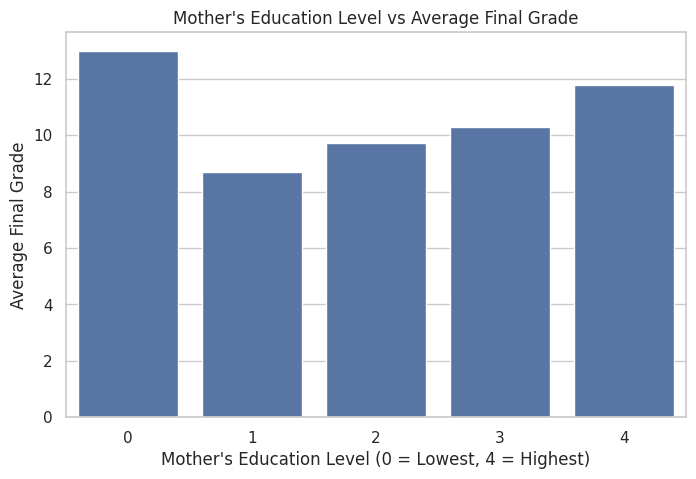

,G3
Medu,
0,13.00
1,8.68
2,9.73
3,10.30
4,11.76


In [14]:

# CELL 12: Mother's education versus final grade

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Medu", y="G3", errorbar=None)
plt.title("Mother's Education Level vs Average Final Grade")
plt.xlabel("Mother's Education Level (0 = Lowest, 4 = Highest)")
plt.ylabel("Average Final Grade")
plt.show()

display(df.groupby("Medu", observed=True)["G3"].mean().round(2))


Visualization 7: Previous grades versus final grades

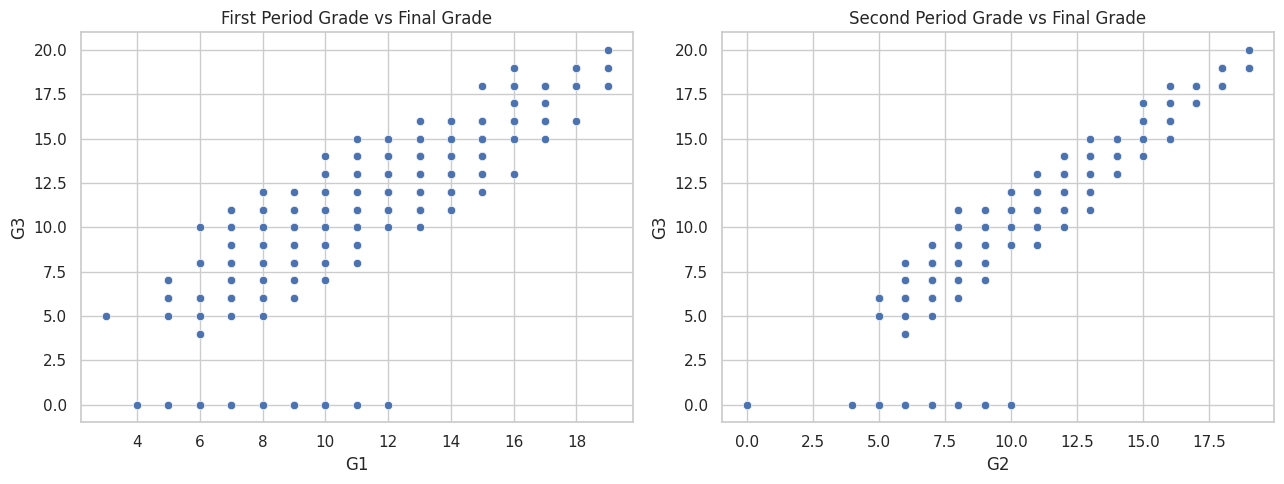

G1 vs G3 correlation: 0.801
G2 vs G3 correlation: 0.905


In [15]:

# CELL 13: Previous grades compared with final grade

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("First Period Grade vs Final Grade")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("Second Period Grade vs Final Grade")

plt.tight_layout()
plt.show()

print("G1 vs G3 correlation:", round(df["G1"].corr(df["G3"]), 3))
print("G2 vs G3 correlation:", round(df["G2"].corr(df["G3"]), 3))


Prepare input features and target

In [16]:

# CELL 14: Separate features and target

X = df.drop(columns=["G3", "Pass"])
y = df["Pass"]

print("Input features:", X.shape)
print("Target:", y.shape)
print("\nInput columns:")
print(X.columns.tolist())


Input features: (395, 32)
Target: (395,)

Input columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


Split into training, validation and test sets

In [17]:

# CELL 15: 70% train, 15% validation, 15% test

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (276, 32)
Validation: (59, 32)
Testing: (60, 32)


Preprocess numerical and categorical features

In [18]:

# CELL 16: Missing-value handling, encoding and scaling

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for TensorFlow
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)
X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)
X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Preprocessing completed!")
print("Processed training shape:", X_train_processed.shape)


Preprocessing completed!
Processed training shape: (276, 58)


Build and train the Deep Learning model

In [19]:

# CELL 17: Create and train MLP model

model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train_np,
    validation_data=(X_val_processed, y_val_np),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6993 - loss: 0.5999 - val_accuracy: 0.6949 - val_loss: 0.5169
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7319 - loss: 0.4811 - val_accuracy: 0.7966 - val_loss: 0.4383
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8225 - loss: 0.4092 - val_accuracy: 0.8644 - val_loss: 0.3800
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8659 - loss: 0.3497 - val_accuracy: 0.8983 - val_loss: 0.3360
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8841 - loss: 0.3093 - val_accuracy: 0.8983 - val_loss: 0.2978
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8986 - loss: 0.2566 - val_accuracy: 0.8814 - val_loss: 0.2757
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9022 - loss: 0.2319 - val_accuracy: 0.8644 - val_loss: 0.2666
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9420 - loss: 0.1878 - val_accuracy: 0.8814 - 

Evaluate the model

In [20]:

# CELL 18: Test-set predictions and evaluation

test_probabilities = model.predict(
    X_test_processed, verbose=0
).ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test_np, test_predictions)
auc = roc_auc_score(y_test_np, test_probabilities)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test ROC-AUC: {auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test_np,
    test_predictions,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))


Test Accuracy: 0.8500
Test ROC-AUC: 0.9075

Classification Report:
              precision    recall  f1-score   support

        Fail       0.82      0.70      0.76        20
        Pass       0.86      0.93      0.89        40

    accuracy                           0.85        60
   macro avg       0.84      0.81      0.82        60
weighted avg       0.85      0.85      0.85        60



Training and validation curves

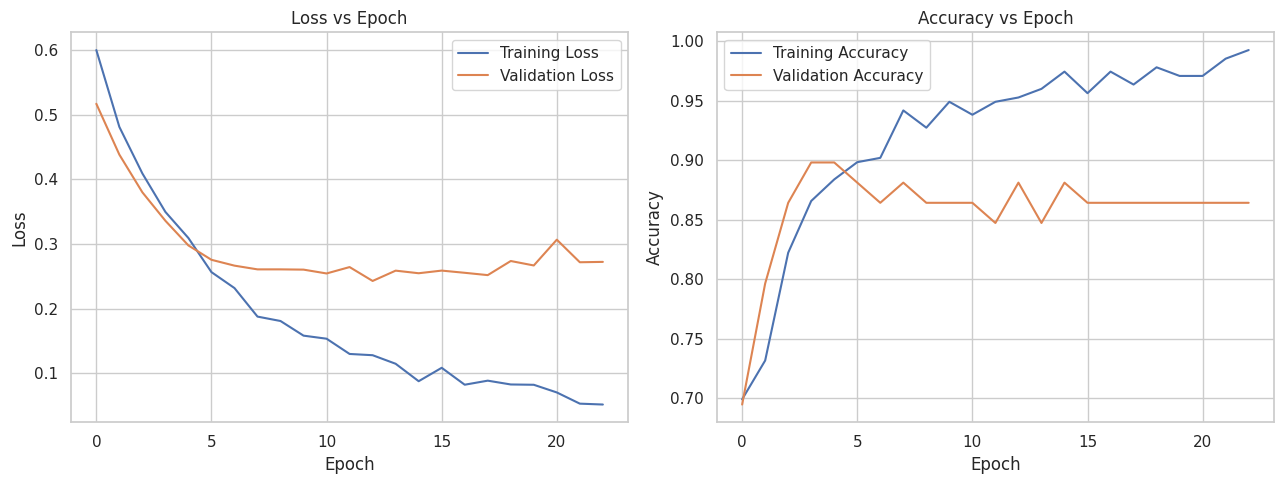

In [21]:

# CELL 19: Loss and accuracy versus epochs

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["loss"], label="Training Loss")
axes[0].plot(history.history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


Confusion matrix

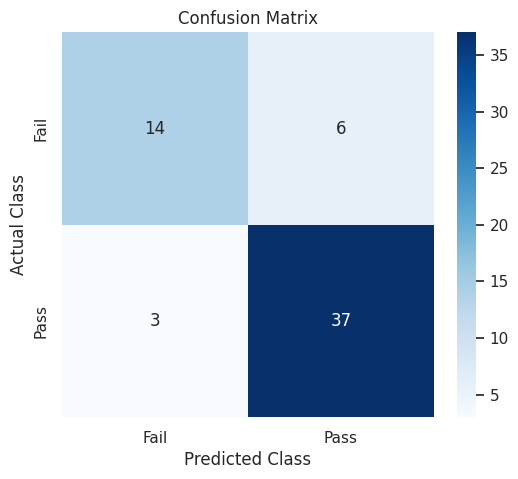

In [22]:

# CELL 20: Confusion matrix

cm = confusion_matrix(y_test_np, test_predictions, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


ROC curve

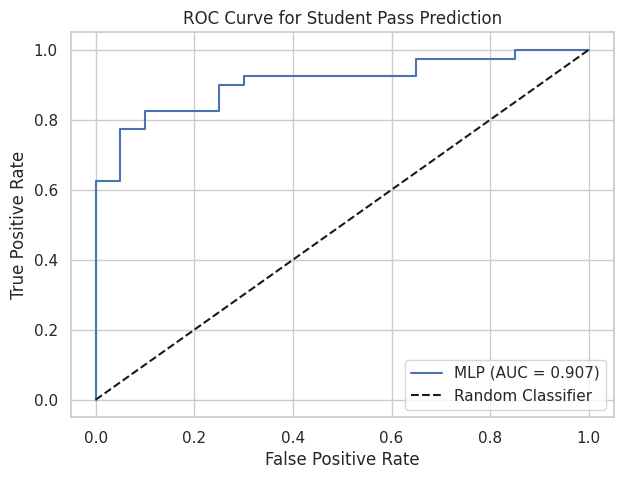

In [23]:

# CELL 21: ROC curve and AUC

fpr, tpr, thresholds = roc_curve(
    y_test_np, test_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MLP (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC Curve for Student Pass Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


Feature importance analysis

,Feature,AUC Decrease
31,G2,0.14375
30,G1,0.11625
14,failures,0.00750
18,activities,0.00750
27,Walc,0.00625
2,age,0.00625
9,Fjob,0.00625
11,guardian,0.00625
0,school,0.00375
25,goout,0.00375


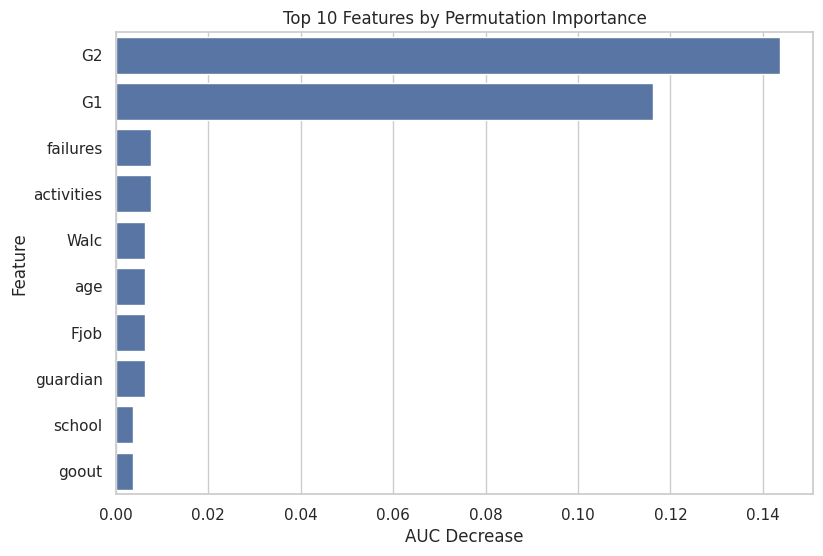

In [24]:

# CELL 22: Permutation feature importance

rng = np.random.default_rng(42)
importance_results = []

baseline_auc = roc_auc_score(y_test_np, test_probabilities)

for col in X_test.columns:
    X_shuffled = X_test.copy()
    X_shuffled[col] = rng.permutation(X_shuffled[col].to_numpy())

    X_shuffled_processed = preprocessor.transform(X_shuffled)
    X_shuffled_processed = np.asarray(
        X_shuffled_processed, dtype=np.float32
    )

    shuffled_probabilities = model.predict(
        X_shuffled_processed, verbose=0
    ).ravel()

    shuffled_auc = roc_auc_score(
        y_test_np, shuffled_probabilities
    )

    importance_results.append({
        "Feature": col,
        "AUC Decrease": baseline_auc - shuffled_auc
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "AUC Decrease", ascending=False
)

display(importance_df.head(10))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(10),
    x="AUC Decrease",
    y="Feature"
)
plt.title("Top 10 Features by Permutation Importance")
plt.show()


Save your project outputs

In [25]:

# CELL 23: Save dataset, results and trained model

df.to_csv("cleaned_student_mathematics.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

model.save("student_performance_mlp.keras")

print("Project outputs saved successfully!")
print("- cleaned_student_mathematics.csv")
print("- feature_importance.csv")
print("- student_performance_mlp.keras")


Project outputs saved successfully!
- cleaned_student_mathematics.csv
- feature_importance.csv
- student_performance_mlp.keras
